# Collinearity check

Before fitting anything: how correlated are the features with each other? Four angles here — correlation matrix, VIF, explicit high-correlation pairs, and hierarchical clustering of the correlated groups.

In [125]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
from statsmodels.stats.outliers_influence import variance_inflation_factor
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')

print('✓ Libraries loaded successfully')

✓ Libraries loaded successfully


## Load data

this is using the nodes correctly

In [126]:
# Load dataset
dataset = pd.read_csv('continuous/data_treated_continuous.csv')

# Load feature lists
diagnosis_variables = []
with open("continuous/diagnosis.txt", "r") as file:
    for line in file:
        diagnosis_variables.append(line.strip())

treatment_variables = []
with open("continuous/treatment.txt", "r") as file:
    for line in file:
        treatment_variables.append(line.strip())

surgery_variables = []
with open("continuous/surgery.txt", "r") as file:
    for line in file:
        surgery_variables.append(line.strip())

# Drop unnamed column if exists
if 'Unnamed: 0' in dataset.columns:
    survival_dataset = dataset.drop('Unnamed: 0', axis=1)
else:
    survival_dataset = dataset.copy()

feature_columns = treatment_variables + diagnosis_variables + surgery_variables

print(f'Dataset shape: {survival_dataset.shape}')
print(f'Number of features: {len(feature_columns)}')
print(f'  Treatment variables: {len(treatment_variables)}')
print(f'  Diagnosis variables: {len(diagnosis_variables)}')

Dataset shape: (3230, 68)
Number of features: 65
  Treatment variables: 14
  Diagnosis variables: 44


In [127]:
# Handle duplicated patients
mask = survival_dataset.duplicated(subset='PERSON_ID', keep=False)

to_remove = (
    survival_dataset[mask]
    .sort_values(['PERSON_ID', 'Survival days'], ascending=[True, True])
    .groupby('PERSON_ID')
    .head(-1)
    .index
)

survival_dataset = survival_dataset.drop(to_remove)

print(f'After removing duplicates: {survival_dataset.shape}')
print(f'Removed {len(to_remove)} duplicate rows')

After removing duplicates: (2970, 68)
Removed 260 duplicate rows


In [128]:
# Extract feature matrix
X = survival_dataset[feature_columns]

print(f'Feature matrix shape: {X.shape}')
print(f'\nData types:')
print(X.dtypes.value_counts())

Feature matrix shape: (2970, 65)

Data types:
float64    57
int64       8
Name: count, dtype: int64


## Correlation matrix

In [129]:
# Calculate correlation matrix
correlation_matrix = X.corr()

print(f'Correlation matrix shape: {correlation_matrix.shape}')
print(f'\nCorrelation statistics:')
print(f'  Mean absolute correlation: {np.abs(correlation_matrix.values[np.triu_indices_from(correlation_matrix.values, k=1)]).mean():.4f}')
print(f'  Max correlation (excluding diagonal): {np.abs(correlation_matrix.values[np.triu_indices_from(correlation_matrix.values, k=1)]).max():.4f}')
print(f'  Min correlation: {np.abs(correlation_matrix.values[np.triu_indices_from(correlation_matrix.values, k=1)]).min():.4f}')

Correlation matrix shape: (65, 65)

Correlation statistics:
  Mean absolute correlation: nan
  Max correlation (excluding diagonal): nan
  Min correlation: nan


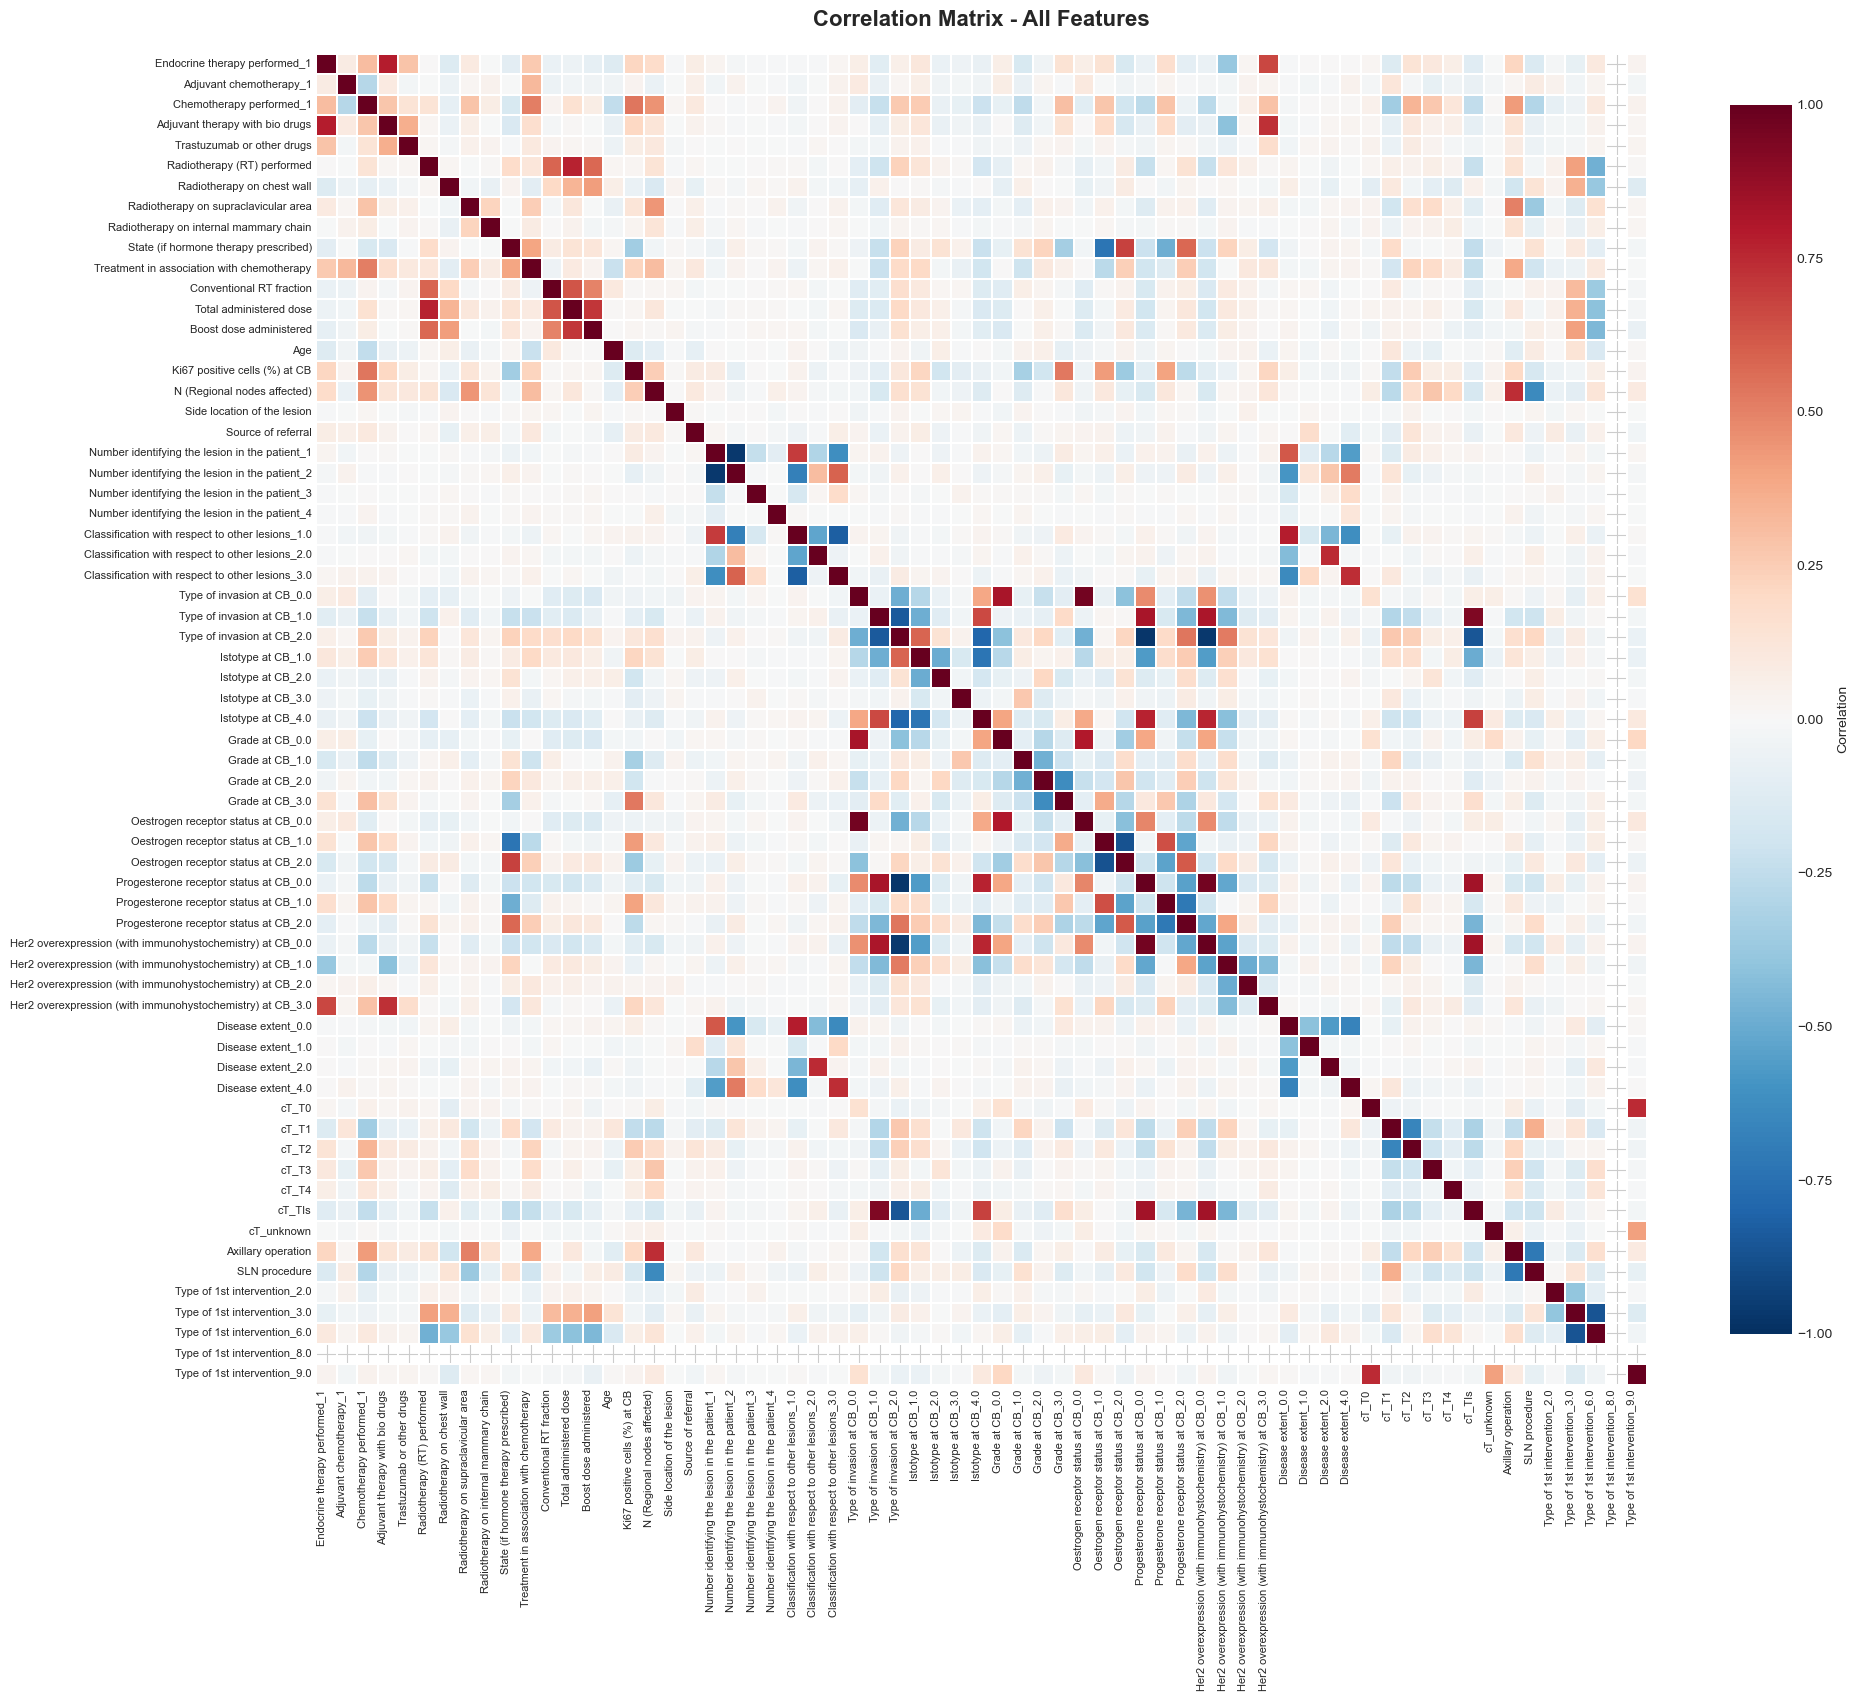

Note: Red = positive correlation, Blue = negative correlation


In [130]:
# Full correlation heatmap (may be large)
fig, ax = plt.subplots(figsize=(20, 18))

# Plot heatmap
sns.heatmap(correlation_matrix, 
            cmap='RdBu_r', 
            center=0, 
            vmin=-1, 
            vmax=1,
            square=True,
            linewidths=0.1,
            cbar_kws={'shrink': 0.8, 'label': 'Correlation'},
            ax=ax)

ax.set_title('Correlation Matrix - All Features', fontsize=16, fontweight='bold', pad=20)
plt.xticks(rotation=90, ha='right', fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.show()

print('Note: Red = positive correlation, Blue = negative correlation')

## High-correlation pairs

Pull out the specific feature pairs that are highly correlated, more actionable than staring at the full matrix.

In [131]:
# Find high correlation pairs
def find_high_correlations(corr_matrix, threshold=0.7):
    """
    Find pairs of features with correlation above threshold.
    """
    high_corr_pairs = []
    
    # Get upper triangle indices (avoid duplicates and diagonal)
    for i in range(len(corr_matrix.columns)):
        for j in range(i+1, len(corr_matrix.columns)):
            if abs(corr_matrix.iloc[i, j]) >= threshold:
                high_corr_pairs.append({
                    'Feature 1': corr_matrix.columns[i],
                    'Feature 2': corr_matrix.columns[j],
                    'Correlation': corr_matrix.iloc[i, j],
                    'Abs Correlation': abs(corr_matrix.iloc[i, j])
                })
    
    # Handle empty results
    if len(high_corr_pairs) == 0:
        return pd.DataFrame(columns=['Feature 1', 'Feature 2', 'Correlation', 'Abs Correlation'])
    
    return pd.DataFrame(high_corr_pairs).sort_values('Abs Correlation', ascending=False)

# Find high correlations at different thresholds
thresholds = [0.9, 0.8, 0.7]

for threshold in thresholds:
    high_corr = find_high_correlations(correlation_matrix, threshold=threshold)
    print(f"\n{'='*80}")
    print(f"HIGH CORRELATION PAIRS (|r| >= {threshold})")
    print(f"{'='*80}")
    print(f"Found {len(high_corr)} pairs\n")
    
    if len(high_corr) > 0:
        print(high_corr.head(20).to_string(index=False))
        if len(high_corr) > 20:
            print(f"\n... and {len(high_corr) - 20} more pairs")
    else:
        print("No pairs found at this threshold")


HIGH CORRELATION PAIRS (|r| >= 0.9)
Found 6 pairs

                                     Feature 1                                                 Feature 2  Correlation  Abs Correlation
                    Type of invasion at CB_2.0                    Progesterone receptor status at CB_0.0    -0.976256         0.976256
                    Type of invasion at CB_0.0                       Oestrogen receptor status at CB_0.0     0.967370         0.967370
        Progesterone receptor status at CB_0.0 Her2 overexpression (with immunohystochemistry) at CB_0.0     0.966873         0.966873
                    Type of invasion at CB_2.0 Her2 overexpression (with immunohystochemistry) at CB_0.0    -0.962793         0.962793
Number identifying the lesion in the patient_1            Number identifying the lesion in the patient_2    -0.961347         0.961347
                    Type of invasion at CB_1.0                                                    cT_TIs     0.935854         0.935854

HI

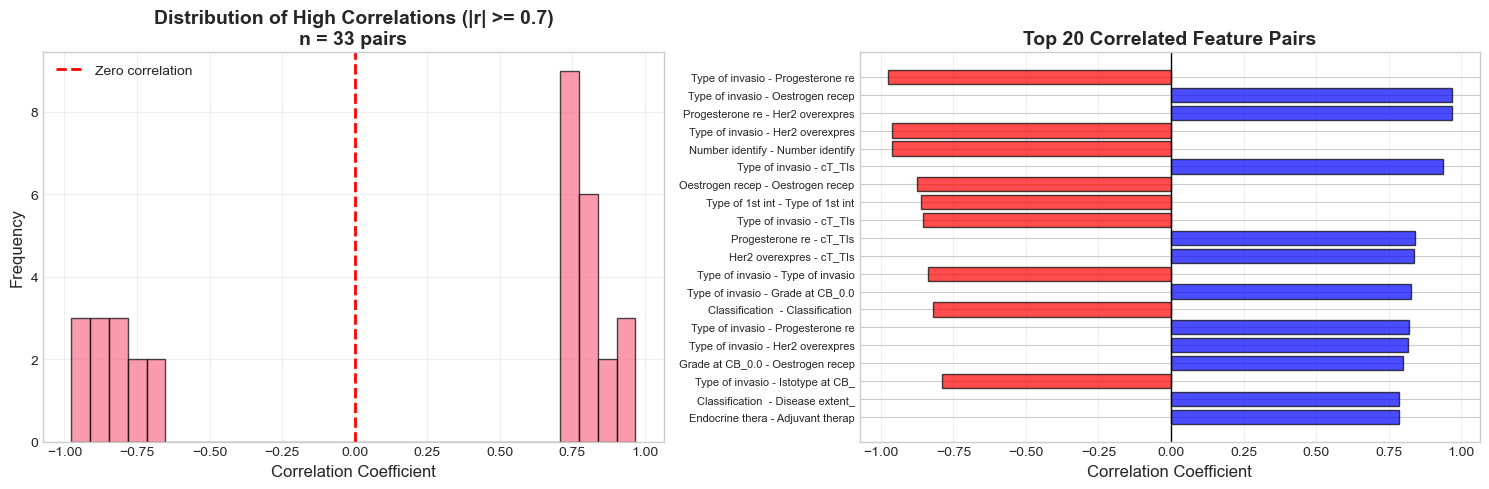

In [132]:
# Store high correlation pairs for analysis
high_corr_70 = find_high_correlations(correlation_matrix, threshold=0.7)

if len(high_corr_70) > 0:
    # Visualize distribution of high correlations
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    
    # Histogram of correlation values
    ax1 = axes[0]
    ax1.hist(high_corr_70['Correlation'], bins=30, edgecolor='black', alpha=0.7)
    ax1.axvline(x=0, color='red', linestyle='--', linewidth=2, label='Zero correlation')
    ax1.set_xlabel('Correlation Coefficient', fontsize=12)
    ax1.set_ylabel('Frequency', fontsize=12)
    ax1.set_title(f'Distribution of High Correlations (|r| >= 0.7)\nn = {len(high_corr_70)} pairs', 
                  fontsize=14, fontweight='bold')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # Top correlated pairs
    ax2 = axes[1]
    top_20 = high_corr_70.head(20).copy()
    top_20['Pair'] = top_20['Feature 1'].str[:15] + ' - ' + top_20['Feature 2'].str[:15]
    
    colors = ['red' if x < 0 else 'blue' for x in top_20['Correlation']]
    ax2.barh(range(len(top_20)), top_20['Correlation'], color=colors, alpha=0.7, edgecolor='black')
    ax2.set_yticks(range(len(top_20)))
    ax2.set_yticklabels(top_20['Pair'], fontsize=8)
    ax2.set_xlabel('Correlation Coefficient', fontsize=12)
    ax2.set_title('Top 20 Correlated Feature Pairs', fontsize=14, fontweight='bold')
    ax2.axvline(x=0, color='black', linestyle='-', linewidth=1)
    ax2.grid(True, alpha=0.3, axis='x')
    ax2.invert_yaxis()
    
    plt.tight_layout()
    plt.show()
else:
    print("No high correlations found (threshold = 0.7)")

## VIF

VIF measures how much a coefficient's variance is inflated by collinearity with other predictors.
- VIF = 1: no correlation
- VIF 1-5: moderate
- VIF > 5: high, worth a look
- VIF > 10: severe, this is a problem

In [133]:
# Calculate VIF for all features
print("Calculating VIF for all features... This may take a while...\n")

vif_data = []
for i, col in enumerate(X.columns):
    try:
        vif = variance_inflation_factor(X.values, i)
        vif_data.append({
            'Feature': col,
            'VIF': vif
        })
        
        if (i + 1) % 10 == 0:
            print(f"Processed {i + 1}/{len(X.columns)} features...")
    except Exception as e:
        print(f"Error calculating VIF for {col}: {e}")
        vif_data.append({
            'Feature': col,
            'VIF': np.nan
        })

vif_df = pd.DataFrame(vif_data).sort_values('VIF', ascending=False)

print(f"\n{'='*80}")
print("VIF ANALYSIS COMPLETE")
print(f"{'='*80}")
print(f"\nVIF Statistics:")
print(f"  Mean VIF: {vif_df['VIF'].mean():.2f}")
print(f"  Median VIF: {vif_df['VIF'].median():.2f}")
print(f"  Max VIF: {vif_df['VIF'].max():.2f}")
print(f"  Min VIF: {vif_df['VIF'].min():.2f}")
print(f"\n  Features with VIF > 10: {(vif_df['VIF'] > 10).sum()}")
print(f"  Features with VIF > 5: {(vif_df['VIF'] > 5).sum()}")
print(f"  Features with VIF > 2: {(vif_df['VIF'] > 2).sum()}")

Calculating VIF for all features... This may take a while...

Processed 10/65 features...
Processed 20/65 features...
Processed 30/65 features...
Processed 20/65 features...
Processed 30/65 features...
Processed 40/65 features...
Processed 50/65 features...
Processed 40/65 features...
Processed 50/65 features...
Processed 60/65 features...

VIF ANALYSIS COMPLETE

VIF Statistics:
  Mean VIF: inf
  Median VIF: inf
  Max VIF: inf
  Min VIF: 1.02

  Features with VIF > 10: 43
  Features with VIF > 5: 45
  Features with VIF > 2: 56
Processed 60/65 features...

VIF ANALYSIS COMPLETE

VIF Statistics:
  Mean VIF: inf
  Median VIF: inf
  Max VIF: inf
  Min VIF: 1.02

  Features with VIF > 10: 43
  Features with VIF > 5: 45
  Features with VIF > 2: 56


In [134]:
# Display high VIF features
print("\n" + "="*80)
print("TOP 30 FEATURES WITH HIGHEST VIF")
print("="*80)
print(vif_df.head(30).to_string(index=False))

# Display features with VIF > 10 (severe multicollinearity)
high_vif = vif_df[vif_df['VIF'] > 10]
if len(high_vif) > 0:
    print(f"\n\n{'='*80}")
    print(f"FEATURES WITH SEVERE MULTICOLLINEARITY (VIF > 10): {len(high_vif)}")
    print(f"{'='*80}")
    print(high_vif.to_string(index=False))
else:
    print("\n✓ No features with VIF > 10 (no severe multicollinearity)")


TOP 30 FEATURES WITH HIGHEST VIF
                                                  Feature  VIF
                                       Istotype at CB_4.0  inf
                                       Istotype at CB_3.0  inf
                                          Grade at CB_1.0  inf
                                          Grade at CB_2.0  inf
                                          Grade at CB_3.0  inf
                      Oestrogen receptor status at CB_0.0  inf
                      Oestrogen receptor status at CB_1.0  inf
                      Oestrogen receptor status at CB_2.0  inf
                   Progesterone receptor status at CB_0.0  inf
                   Progesterone receptor status at CB_1.0  inf
                   Progesterone receptor status at CB_2.0  inf
Her2 overexpression (with immunohystochemistry) at CB_0.0  inf
Her2 overexpression (with immunohystochemistry) at CB_1.0  inf
Her2 overexpression (with immunohystochemistry) at CB_2.0  inf
Her2 overexpression (

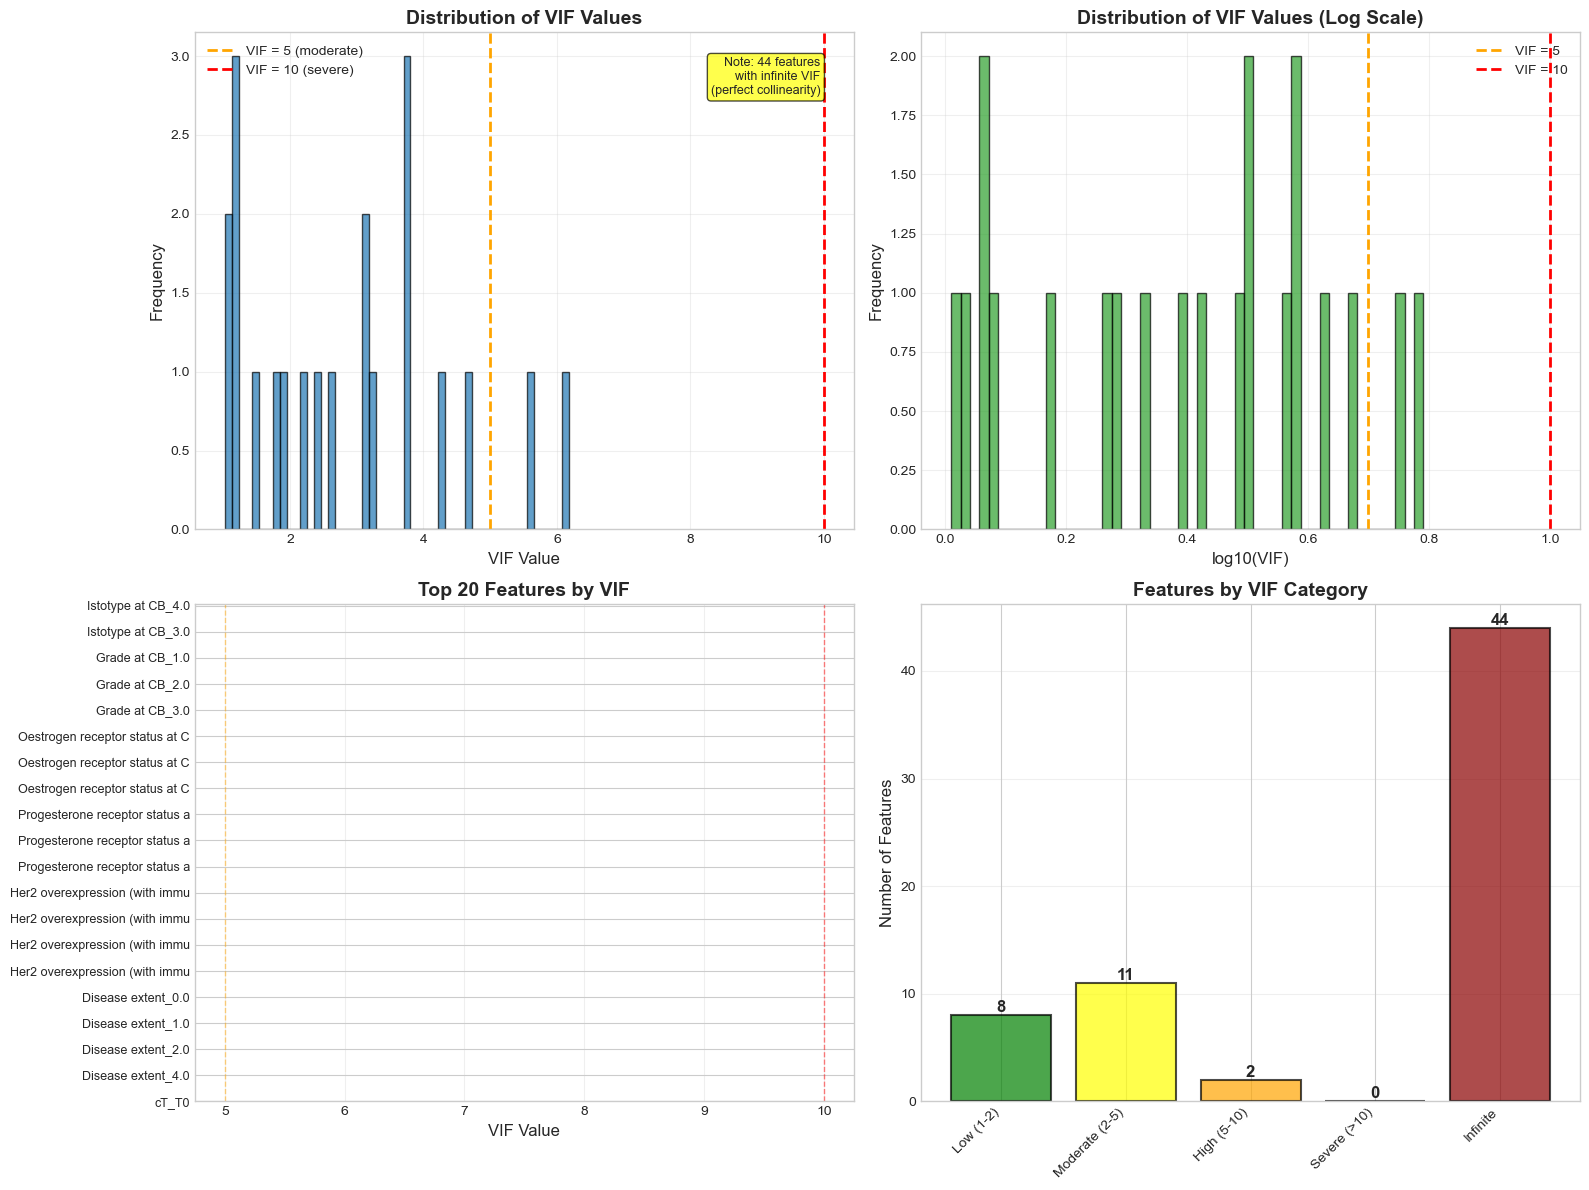

In [135]:
# Visualize VIF distribution
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Filter out infinite VIF values for visualization
vif_finite = vif_df[np.isfinite(vif_df['VIF'])]['VIF']
vif_infinite_count = (~np.isfinite(vif_df['VIF'])).sum()

# 1. VIF distribution (histogram)
ax1 = axes[0, 0]
if len(vif_finite) > 0:
    ax1.hist(vif_finite, bins=50, edgecolor='black', alpha=0.7, color='tab:blue')
    ax1.axvline(x=5, color='orange', linestyle='--', linewidth=2, label='VIF = 5 (moderate)')
    ax1.axvline(x=10, color='red', linestyle='--', linewidth=2, label='VIF = 10 (severe)')
    if vif_infinite_count > 0:
        ax1.text(0.95, 0.95, f'Note: {vif_infinite_count} features\nwith infinite VIF\n(perfect collinearity)',
                transform=ax1.transAxes, ha='right', va='top',
                bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.7),
                fontsize=9)
ax1.set_xlabel('VIF Value', fontsize=12)
ax1.set_ylabel('Frequency', fontsize=12)
ax1.set_title('Distribution of VIF Values', fontsize=14, fontweight='bold')
ax1.legend()
ax1.grid(True, alpha=0.3)

# 2. VIF distribution (log scale)
ax2 = axes[0, 1]
if len(vif_finite) > 0:
    vif_positive = vif_finite[vif_finite > 0]
    if len(vif_positive) > 0:
        ax2.hist(np.log10(vif_positive), bins=50, edgecolor='black', alpha=0.7, color='tab:green')
        ax2.axvline(x=np.log10(5), color='orange', linestyle='--', linewidth=2, label='VIF = 5')
        ax2.axvline(x=np.log10(10), color='red', linestyle='--', linewidth=2, label='VIF = 10')
ax2.set_xlabel('log10(VIF)', fontsize=12)
ax2.set_ylabel('Frequency', fontsize=12)
ax2.set_title('Distribution of VIF Values (Log Scale)', fontsize=14, fontweight='bold')
ax2.legend()
ax2.grid(True, alpha=0.3)

# 3. Top 20 highest VIF features
ax3 = axes[1, 0]
top_20_vif = vif_df.head(20)
colors_vif = ['red' if x > 10 else 'orange' if x > 5 else 'green' for x in top_20_vif['VIF']]
ax3.barh(range(len(top_20_vif)), top_20_vif['VIF'], color=colors_vif, alpha=0.7, edgecolor='black')
ax3.set_yticks(range(len(top_20_vif)))
ax3.set_yticklabels([f[:30] for f in top_20_vif['Feature']], fontsize=9)
ax3.set_xlabel('VIF Value', fontsize=12)
ax3.set_title('Top 20 Features by VIF', fontsize=14, fontweight='bold')
ax3.axvline(x=5, color='orange', linestyle='--', linewidth=1, alpha=0.5)
ax3.axvline(x=10, color='red', linestyle='--', linewidth=1, alpha=0.5)
ax3.grid(True, alpha=0.3, axis='x')
ax3.invert_yaxis()

# 4. VIF categories
ax4 = axes[1, 1]
# Handle infinite VIF values separately
vif_finite_mask = np.isfinite(vif_df['VIF'])
vif_for_categories = vif_df[vif_finite_mask]['VIF']

vif_categories = pd.cut(vif_for_categories, 
                        bins=[0, 2, 5, 10, 1000],
                        labels=['Low (1-2)', 'Moderate (2-5)', 'High (5-10)', 'Severe (>10)'])
category_counts = vif_categories.value_counts().sort_index()

# Add infinite VIF count if any
if vif_infinite_count > 0:
    category_counts = pd.concat([category_counts, pd.Series({'Infinite': vif_infinite_count})])

colors_cat = ['green', 'yellow', 'orange', 'red', 'darkred']
bars = ax4.bar(range(len(category_counts)), category_counts.values, 
               color=colors_cat[:len(category_counts)], alpha=0.7, edgecolor='black', linewidth=1.5)
ax4.set_xticks(range(len(category_counts)))
ax4.set_xticklabels(category_counts.index, rotation=45, ha='right', fontsize=10)
ax4.set_ylabel('Number of Features', fontsize=12)
ax4.set_title('Features by VIF Category', fontsize=14, fontweight='bold')
ax4.grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for bar, count in zip(bars, category_counts.values):
    height = bar.get_height()
    ax4.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(count)}',
             ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

## Hierarchical clustering

Cluster features by correlation to see which ones are effectively grouping together.

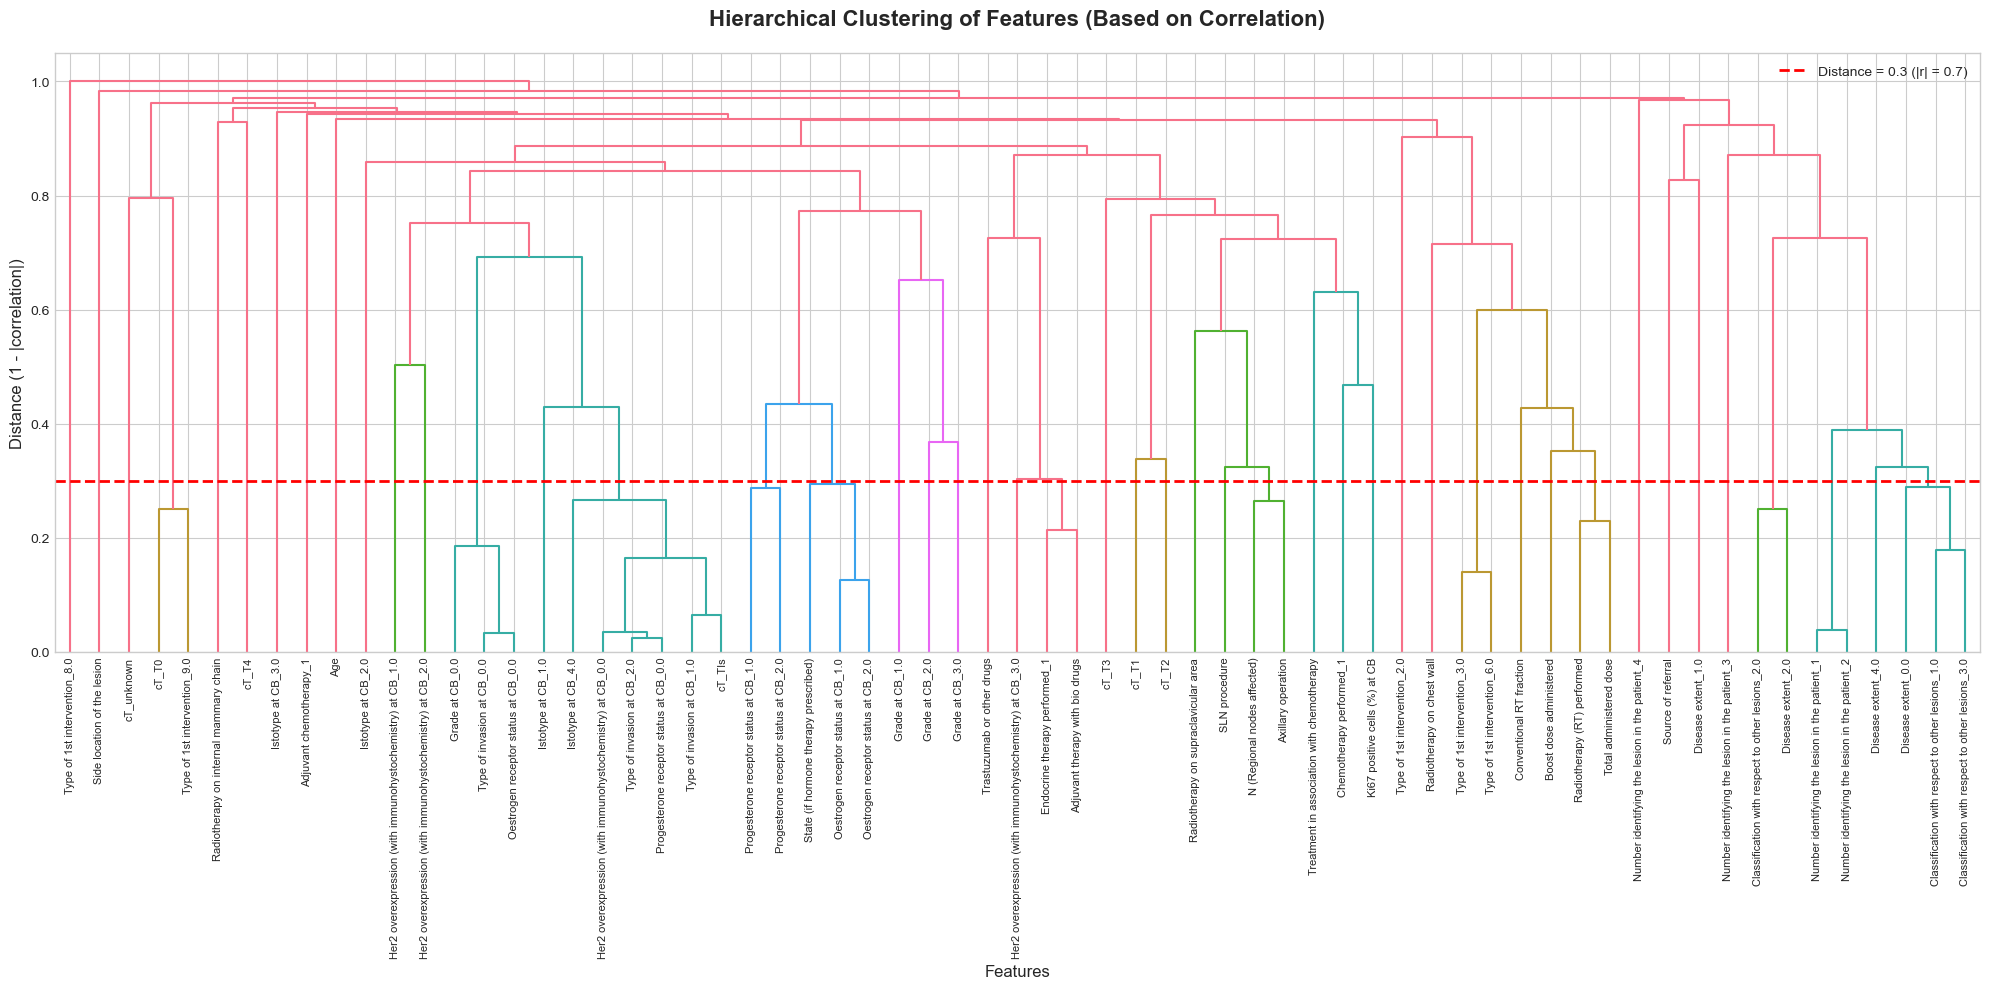

Note: Features that cluster together (low distance) are highly correlated
Consider selecting one representative feature from each tight cluster


In [136]:
# Hierarchical clustering based on correlation
# Convert correlation to distance: distance = 1 - |correlation|
corr_distance = 1 - np.abs(correlation_matrix)

# Handle NaN/infinite values - replace with maximum distance (1)
corr_distance = corr_distance.fillna(1.0)
corr_distance = corr_distance.replace([np.inf, -np.inf], 1.0)

# Convert to condensed distance matrix for clustering
condensed_dist = squareform(corr_distance, checks=False)

# Perform hierarchical clustering
linkage_matrix = hierarchy.linkage(condensed_dist, method='average')

# Plot dendrogram
fig, ax = plt.subplots(figsize=(20, 10))

dendro = hierarchy.dendrogram(
    linkage_matrix,
    labels=correlation_matrix.columns,
    leaf_rotation=90,
    leaf_font_size=8,
    ax=ax
)

ax.set_title('Hierarchical Clustering of Features (Based on Correlation)', 
             fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Features', fontsize=12)
ax.set_ylabel('Distance (1 - |correlation|)', fontsize=12)
ax.axhline(y=0.3, color='red', linestyle='--', linewidth=2, label='Distance = 0.3 (|r| = 0.7)')
ax.legend()

plt.tight_layout()
plt.show()

print("Note: Features that cluster together (low distance) are highly correlated")
print("Consider selecting one representative feature from each tight cluster")

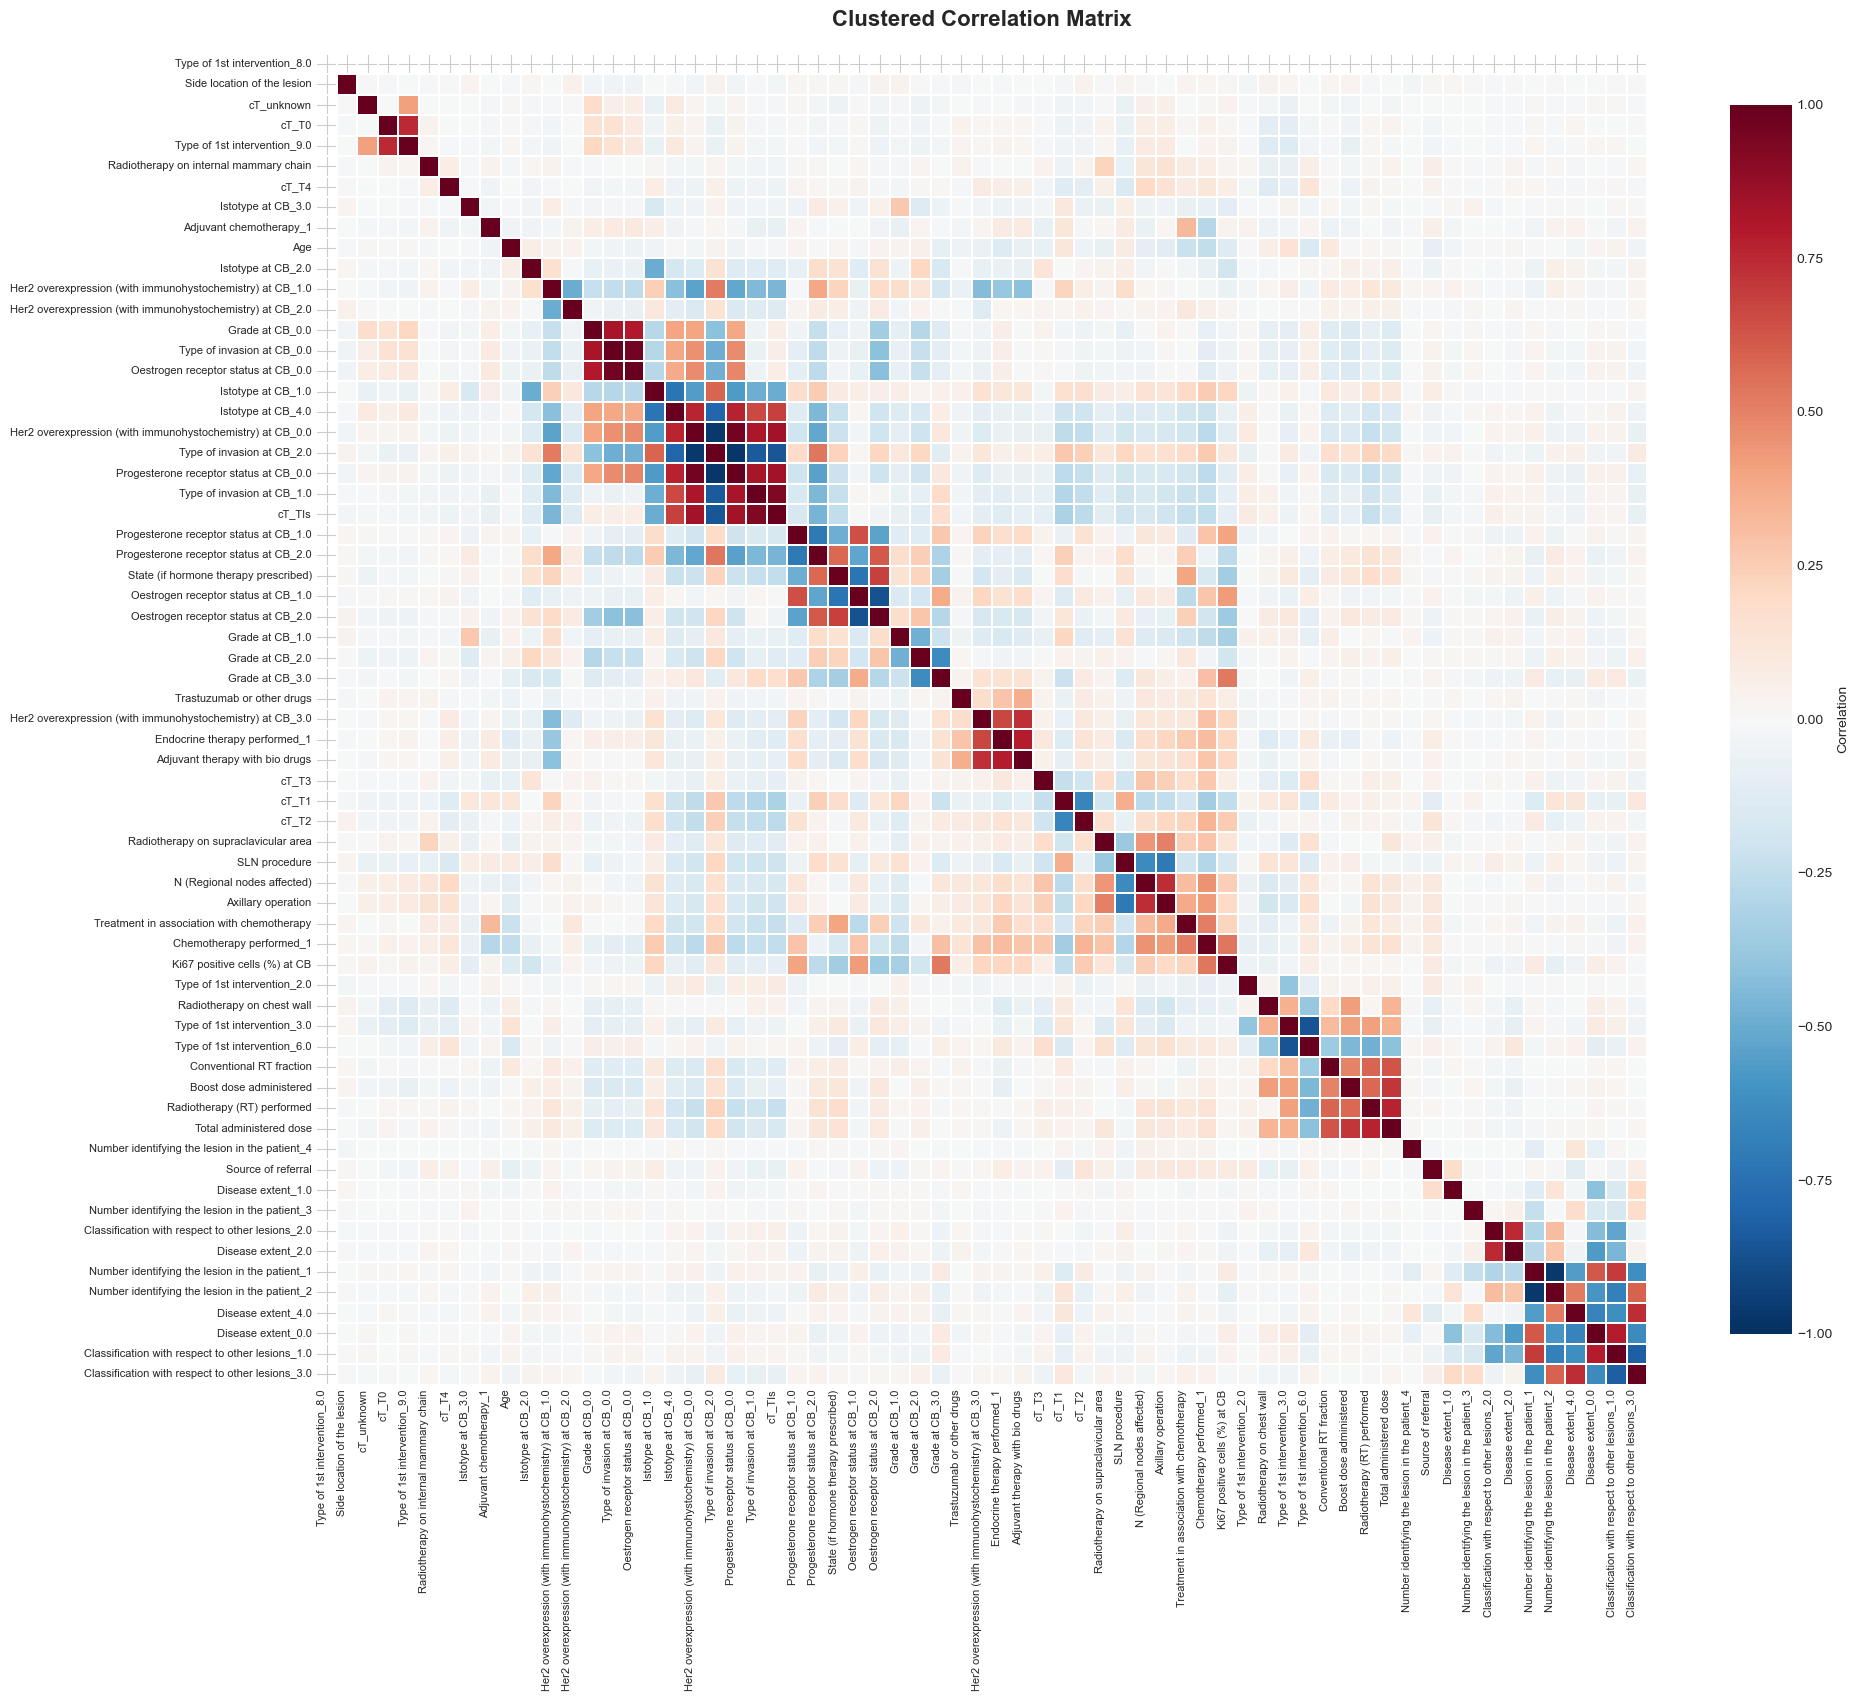

Note: Features are reordered by hierarchical clustering
Dark red/blue blocks indicate groups of highly correlated features


In [137]:
# Create clustered heatmap
# Reorder correlation matrix based on clustering
cluster_order = dendro['leaves']
clustered_corr = correlation_matrix.iloc[cluster_order, cluster_order]

fig, ax = plt.subplots(figsize=(20, 18))

sns.heatmap(clustered_corr, 
            cmap='RdBu_r', 
            center=0, 
            vmin=-1, 
            vmax=1,
            square=True,
            linewidths=0.1,
            cbar_kws={'shrink': 0.8, 'label': 'Correlation'},
            ax=ax)

ax.set_title('Clustered Correlation Matrix', fontsize=16, fontweight='bold', pad=20)
plt.xticks(rotation=90, ha='right', fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.show()

print("Note: Features are reordered by hierarchical clustering")
print("Dark red/blue blocks indicate groups of highly correlated features")

## Summary and recommendations

In [138]:
print("="*80)
print("COLLINEARITY ANALYSIS SUMMARY")
print("="*80)

print(f"\n1. DATASET:")
print(f"   - Total features: {len(feature_columns)}")
print(f"   - Samples: {X.shape[0]}")

print(f"\n2. CORRELATION ANALYSIS:")
high_corr_90 = find_high_correlations(correlation_matrix, threshold=0.9)
high_corr_80 = find_high_correlations(correlation_matrix, threshold=0.8)
high_corr_70 = find_high_correlations(correlation_matrix, threshold=0.7)
print(f"   - Pairs with |r| >= 0.9: {len(high_corr_90)}")
print(f"   - Pairs with |r| >= 0.8: {len(high_corr_80)}")
print(f"   - Pairs with |r| >= 0.7: {len(high_corr_70)}")

print(f"\n3. VIF ANALYSIS:")
vif_infinite = (~np.isfinite(vif_df['VIF'])).sum()
vif_finite_mask = np.isfinite(vif_df['VIF'])
print(f"   - Features with infinite VIF (perfect collinearity): {vif_infinite}")
print(f"   - Features with VIF > 10 (severe): {(vif_df[vif_finite_mask]['VIF'] > 10).sum()}")
print(f"   - Features with VIF > 5 (high): {(vif_df[vif_finite_mask]['VIF'] > 5).sum()}")
print(f"   - Features with VIF > 2 (moderate): {(vif_df[vif_finite_mask]['VIF'] > 2).sum()}")
if vif_finite_mask.sum() > 0:
    print(f"   - Mean VIF (finite only): {vif_df[vif_finite_mask]['VIF'].mean():.2f}")

print(f"\n4. RECOMMENDATIONS:")

if vif_infinite > 0:
    print(f"   🚨 PERFECT multicollinearity detected! ({vif_infinite} features with infinite VIF)")
    print(f"   → These features are perfectly predictable from other features")
    print(f"   → MUST remove these features before modeling")
    print(f"   → Check correlation matrix to identify the exact relationships")
elif (vif_df[vif_finite_mask]['VIF'] > 10).sum() > 0:
    print(f"   ⚠ SEVERE multicollinearity detected!")
    print(f"   → Consider removing features with VIF > 10")
    print(f"   → Or use dimensionality reduction (PCA)")
    print(f"   → Or use regularization (Lasso, Ridge, Elastic Net)")
elif (vif_df[vif_finite_mask]['VIF'] > 5).sum() > 0:
    print(f"   ⚠ HIGH multicollinearity detected")
    print(f"   → Monitor features with VIF > 5")
    print(f"   → Consider using regularization methods")
else:
    print(f"   ✓ Multicollinearity is manageable")
    print(f"   → No immediate action required")

if len(high_corr_90) > 0:
    print(f"\n   → {len(high_corr_90)} feature pairs have |r| >= 0.9 (very high correlation)")
    print(f"   → Consider removing one feature from each pair")

print(f"\n5. NEXT STEPS:")
print(f"   1. Review high VIF features (VIF > 10)")
print(f"   2. Examine highly correlated pairs (|r| >= 0.9)")
print(f"   3. Use domain knowledge to select features")
print(f"   4. Apply regularization (Lasso, Ridge) to handle collinearity")
print(f"   5. Consider feature selection methods")
print(f"   6. Monitor model stability across cross-validation folds")

print("\n" + "="*80)

COLLINEARITY ANALYSIS SUMMARY

1. DATASET:
   - Total features: 65
   - Samples: 2970

2. CORRELATION ANALYSIS:
   - Pairs with |r| >= 0.9: 6
   - Pairs with |r| >= 0.8: 17
   - Pairs with |r| >= 0.7: 33

3. VIF ANALYSIS:
   - Features with infinite VIF (perfect collinearity): 44
   - Features with VIF > 10 (severe): 0
   - Features with VIF > 5 (high): 2
   - Features with VIF > 2 (moderate): 13
   - Mean VIF (finite only): 2.84

4. RECOMMENDATIONS:
   🚨 PERFECT multicollinearity detected! (44 features with infinite VIF)
   → These features are perfectly predictable from other features
   → MUST remove these features before modeling
   → Check correlation matrix to identify the exact relationships

   → 6 feature pairs have |r| >= 0.9 (very high correlation)
   → Consider removing one feature from each pair

5. NEXT STEPS:
   1. Review high VIF features (VIF > 10)
   2. Examine highly correlated pairs (|r| >= 0.9)
   3. Use domain knowledge to select features
   4. Apply regularizatio

In [139]:
# Save results to CSV for further analysis
vif_df.to_csv('vif_analysis.csv', index=False)
high_corr_70.to_csv('high_correlations_70.csv', index=False)

print("✓ Results saved:")
print("  - vif_analysis.csv")
print("  - high_correlations_70.csv")

✓ Results saved:
  - vif_analysis.csv
  - high_correlations_70.csv


## Dropping collinear features

Iteratively strip out anything with severe VIF/correlation to get a cleaner feature set.

In [140]:
# Strategy: Remove features with infinite VIF and high correlation iteratively
print("=" * 80)
print("FEATURE REMOVAL STRATEGY")
print("=" * 80)

# Step 1: Remove features with infinite VIF
features_to_remove = set()
infinite_vif_features = vif_df[~np.isfinite(vif_df['VIF'])]['Feature'].tolist()

print(f"\nStep 1: Remove features with INFINITE VIF")
print(f"Found {len(infinite_vif_features)} features with infinite VIF (perfect collinearity)")

if len(infinite_vif_features) > 0:
    # For features with infinite VIF, keep the first one in each correlated group
    # and remove the rest
    for feature in infinite_vif_features:
        if feature in X.columns:
            # Check if this feature is highly correlated with any kept feature
            correlations_with_feature = correlation_matrix[feature].abs()
            correlations_with_feature = correlations_with_feature.drop(feature)  # Exclude self
            
            # Find features highly correlated (>0.95) with this one
            highly_correlated = correlations_with_feature[correlations_with_feature > 0.95].index.tolist()
            
            # If any highly correlated feature is already removed or this is the first, keep it
            # Otherwise, mark for removal
            if any(f in features_to_remove for f in highly_correlated):
                # Keep this feature, don't add to removal list
                pass
            elif len(highly_correlated) == 0:
                # No high correlations found, might be due to other features
                # Remove this feature
                features_to_remove.add(feature)
            else:
                # This is first in group, keep it; mark others for removal
                for corr_feature in highly_correlated:
                    if corr_feature != feature and corr_feature in infinite_vif_features:
                        features_to_remove.add(corr_feature)

print(f"Marked {len(features_to_remove)} features for removal based on infinite VIF\n")

# Step 2: Remove features from highly correlated pairs (|r| > 0.9)
print(f"Step 2: Remove one feature from each highly correlated pair (|r| > 0.9)")

high_corr_pairs = find_high_correlations(correlation_matrix, threshold=0.9)
print(f"Found {len(high_corr_pairs)} pairs with |r| > 0.9")

for _, row in high_corr_pairs.iterrows():
    feat1 = row['Feature 1']
    feat2 = row['Feature 2']
    
    # Skip if already marked for removal
    if feat1 in features_to_remove or feat2 in features_to_remove:
        continue
    
    # Choose which one to remove: prefer to keep features with lower VIF
    vif1 = vif_df[vif_df['Feature'] == feat1]['VIF'].values[0] if feat1 in vif_df['Feature'].values else np.inf
    vif2 = vif_df[vif_df['Feature'] == feat2]['VIF'].values[0] if feat2 in vif_df['Feature'].values else np.inf
    
    # Remove the one with higher VIF (or feat2 if both infinite)
    if np.isfinite(vif1) and np.isfinite(vif2):
        if vif1 > vif2:
            features_to_remove.add(feat1)
        else:
            features_to_remove.add(feat2)
    elif np.isfinite(vif1):
        features_to_remove.add(feat2)
    elif np.isfinite(vif2):
        features_to_remove.add(feat1)
    else:
        # Both infinite, keep first one
        features_to_remove.add(feat2)

print(f"Total features marked for removal: {len(features_to_remove)}\n")

# Step 3: Create cleaned dataset
print(f"Step 3: Create cleaned dataset")
features_to_keep = [f for f in feature_columns if f not in features_to_remove]

print(f"Original features: {len(feature_columns)}")
print(f"Features removed: {len(features_to_remove)}")
print(f"Features kept: {len(features_to_keep)}")

# Show removed features
if len(features_to_remove) > 0:
    print(f"\nRemoved features:")
    for i, feat in enumerate(sorted(features_to_remove), 1):
        vif_val = vif_df[vif_df['Feature'] == feat]['VIF'].values[0] if feat in vif_df['Feature'].values else 'N/A'
        if np.isfinite(vif_val):
            print(f"  {i}. {feat} (VIF: {vif_val:.2f})")
        else:
            print(f"  {i}. {feat} (VIF: infinite)")

print("\n" + "=" * 80)

FEATURE REMOVAL STRATEGY

Step 1: Remove features with INFINITE VIF
Found 44 features with infinite VIF (perfect collinearity)
Marked 43 features for removal based on infinite VIF

Step 2: Remove one feature from each highly correlated pair (|r| > 0.9)
Found 6 pairs with |r| > 0.9
Total features marked for removal: 43

Step 3: Create cleaned dataset
Original features: 65
Features removed: 43
Features kept: 22

Removed features:
  1. Classification with respect to other lesions_1.0 (VIF: infinite)
  2. Classification with respect to other lesions_2.0 (VIF: infinite)
  3. Classification with respect to other lesions_3.0 (VIF: infinite)
  4. Disease extent_0.0 (VIF: infinite)
  5. Disease extent_1.0 (VIF: infinite)
  6. Disease extent_2.0 (VIF: infinite)
  7. Disease extent_4.0 (VIF: infinite)
  8. Grade at CB_0.0 (VIF: infinite)
  9. Grade at CB_1.0 (VIF: infinite)
  10. Grade at CB_2.0 (VIF: infinite)
  11. Grade at CB_3.0 (VIF: infinite)
  12. Her2 overexpression (with immunohystochemi

In [141]:
# Verify the cleaned dataset
X_clean = X[features_to_keep].copy()

print("=" * 80)
print("CLEANED DATASET VERIFICATION")
print("=" * 80)

# Recalculate VIF for cleaned dataset
print("\nRecalculating VIF for cleaned dataset...\n")

vif_clean_data = []
for i, col in enumerate(X_clean.columns):
    try:
        vif = variance_inflation_factor(X_clean.values, i)
        vif_clean_data.append({
            'Feature': col,
            'VIF': vif
        })
        if (i + 1) % 10 == 0:
            print(f"Processed {i + 1}/{len(X_clean.columns)} features...")
    except Exception as e:
        vif_clean_data.append({
            'Feature': col,
            'VIF': np.nan
        })

vif_clean_df = pd.DataFrame(vif_clean_data).sort_values('VIF', ascending=False)

print(f"\n{'='*80}")
print("CLEANED DATASET VIF STATISTICS")
print(f"{'='*80}")

vif_clean_finite_mask = np.isfinite(vif_clean_df['VIF'])
vif_clean_infinite = (~np.isfinite(vif_clean_df['VIF'])).sum()

print(f"\nFeatures in cleaned dataset: {len(X_clean.columns)}")
print(f"Features with infinite VIF: {vif_clean_infinite}")
print(f"Features with VIF > 10: {(vif_clean_df[vif_clean_finite_mask]['VIF'] > 10).sum()}")
print(f"Features with VIF > 5: {(vif_clean_df[vif_clean_finite_mask]['VIF'] > 5).sum()}")
print(f"Mean VIF (finite): {vif_clean_df[vif_clean_finite_mask]['VIF'].mean():.2f}")
print(f"Median VIF (finite): {vif_clean_df[vif_clean_finite_mask]['VIF'].median():.2f}")
print(f"Max VIF (finite): {vif_clean_df[vif_clean_finite_mask]['VIF'].max():.2f}")

# Check correlations in cleaned dataset
corr_clean = X_clean.corr()
high_corr_clean_df = find_high_correlations(corr_clean, threshold=0.9)

print(f"\nCorrelation Analysis:")
print(f"  Pairs with |r| >= 0.9: {len(high_corr_clean_df)}")
print(f"  Mean absolute correlation: {np.abs(corr_clean.values[np.triu_indices_from(corr_clean.values, k=1)]).mean():.4f}")
print(f"  Max correlation: {np.abs(corr_clean.values[np.triu_indices_from(corr_clean.values, k=1)]).max():.4f}")

print("\n" + "=" * 80)

# Show improvement
print("\nIMPROVEMENT SUMMARY:")
print(f"  Original infinite VIF features: {vif_infinite} → {vif_clean_infinite}")
print(f"  Original VIF > 10: {(vif_df[vif_finite_mask]['VIF'] > 10).sum()} → {(vif_clean_df[vif_clean_finite_mask]['VIF'] > 10).sum()}")
print(f"  Original mean VIF: {vif_df[vif_finite_mask]['VIF'].mean():.2f} → {vif_clean_df[vif_clean_finite_mask]['VIF'].mean():.2f}")
print(f"  Original |r| >= 0.9 pairs: {len(high_corr_90)} → {len(high_corr_clean_df)}")
print("\n" + "=" * 80)

CLEANED DATASET VERIFICATION

Recalculating VIF for cleaned dataset...

Processed 10/22 features...
Processed 20/22 features...

CLEANED DATASET VIF STATISTICS

Features in cleaned dataset: 22
Features with infinite VIF: 0
Features with VIF > 10: 5
Features with VIF > 5: 11
Mean VIF (finite): 6.99
Median VIF (finite): 4.80
Max VIF (finite): 24.37

Correlation Analysis:
  Pairs with |r| >= 0.9: 0
  Mean absolute correlation: 0.1292
  Max correlation: 0.7860


IMPROVEMENT SUMMARY:
  Original infinite VIF features: 44 → 0
  Original VIF > 10: 0 → 5
  Original mean VIF: 2.84 → 6.99
  Original |r| >= 0.9 pairs: 6 → 0

Processed 10/22 features...
Processed 20/22 features...

CLEANED DATASET VIF STATISTICS

Features in cleaned dataset: 22
Features with infinite VIF: 0
Features with VIF > 10: 5
Features with VIF > 5: 11
Mean VIF (finite): 6.99
Median VIF (finite): 4.80
Max VIF (finite): 24.37

Correlation Analysis:
  Pairs with |r| >= 0.9: 0
  Mean absolute correlation: 0.1292
  Max correlatio

In [142]:
# Save cleaned dataset
# Determine the survival columns (columns not in feature_columns)
survival_cols = [col for col in survival_dataset.columns if col not in feature_columns]
print(f"Survival columns found: {survival_cols}")

survival_dataset_clean = survival_dataset[survival_cols + features_to_keep].copy()

output_path = 'data_treated_clean.csv'
survival_dataset_clean.to_csv(output_path, index=False)

print("\n" + "=" * 80)
print(f"CLEANED DATASET SAVED")
print("=" * 80)
print(f"\nFile: {output_path}")
print(f"Samples: {len(survival_dataset_clean)}")
print(f"Features: {len(features_to_keep)} + {len(survival_cols)} (survival columns)")
print(f"Total columns: {len(survival_dataset_clean.columns)}")
print("\nFeatures removed from original dataset:")
print(f"  Total removed: {len(features_to_remove)}")
print(f"  Retained: {len(features_to_keep)} / {len(X.columns)} ({100*len(features_to_keep)/len(X.columns):.1f}%)")
print("\n" + "=" * 80)

# Save VIF results
vif_clean_df.to_csv('vif_analysis_clean.csv', index=False)
print(f"\nVIF analysis saved to: vif_analysis_clean.csv")

# Save feature lists
with open('features_removed.txt', 'w') as f:
    for feature in sorted(features_to_remove):
        f.write(f"{feature}\n")

with open('features_retained.txt', 'w') as f:
    for feature in sorted(features_to_keep):
        f.write(f"{feature}\n")

print(f"Features removed saved to: features_removed.txt")
print(f"Features retained saved to: features_retained.txt")

Survival columns found: ['PERSON_ID', 'Regional LN recurrence', 'Survival days']

CLEANED DATASET SAVED

File: data_treated_clean.csv
Samples: 2970
Features: 22 + 3 (survival columns)
Total columns: 25

Features removed from original dataset:
  Total removed: 43
  Retained: 22 / 65 (33.8%)


VIF analysis saved to: vif_analysis_clean.csv
Features removed saved to: features_removed.txt
Features retained saved to: features_retained.txt

CLEANED DATASET SAVED

File: data_treated_clean.csv
Samples: 2970
Features: 22 + 3 (survival columns)
Total columns: 25

Features removed from original dataset:
  Total removed: 43
  Retained: 22 / 65 (33.8%)


VIF analysis saved to: vif_analysis_clean.csv
Features removed saved to: features_removed.txt
Features retained saved to: features_retained.txt


## After cleaning

Check how much the VIF distribution actually improved.

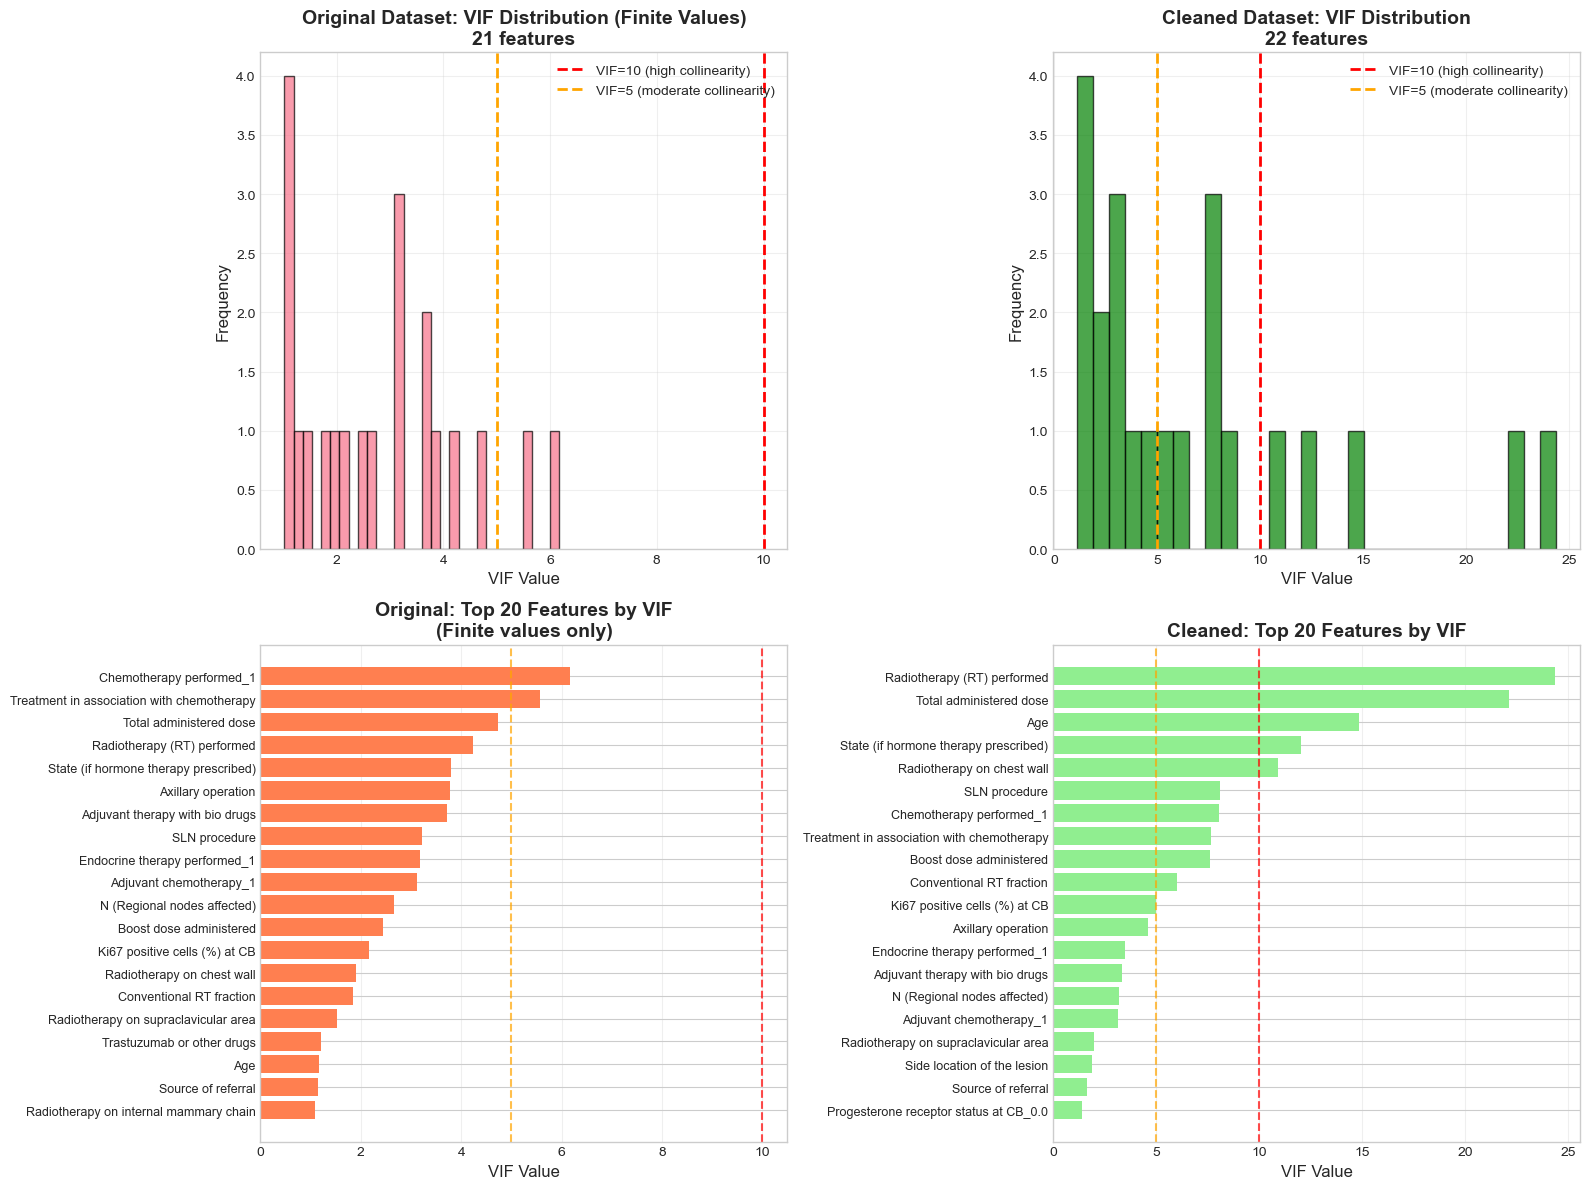


Comparison plot saved to: vif_comparison.png


In [143]:
# Compare VIF distributions before and after cleaning
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Before: VIF distribution (finite values only)
vif_finite_original = vif_df[np.isfinite(vif_df['VIF'])]['VIF']
ax = axes[0, 0]
ax.hist(vif_finite_original, bins=30, edgecolor='black', alpha=0.7)
ax.axvline(x=10, color='red', linestyle='--', linewidth=2, label='VIF=10 (high collinearity)')
ax.axvline(x=5, color='orange', linestyle='--', linewidth=2, label='VIF=5 (moderate collinearity)')
ax.set_xlabel('VIF Value', fontsize=12)
ax.set_ylabel('Frequency', fontsize=12)
ax.set_title(f'Original Dataset: VIF Distribution (Finite Values)\n{len(vif_finite_original)} features', fontsize=14, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# After: VIF distribution
vif_finite_clean = vif_clean_df[np.isfinite(vif_clean_df['VIF'])]['VIF']
ax = axes[0, 1]
ax.hist(vif_finite_clean, bins=30, edgecolor='black', alpha=0.7, color='green')
ax.axvline(x=10, color='red', linestyle='--', linewidth=2, label='VIF=10 (high collinearity)')
ax.axvline(x=5, color='orange', linestyle='--', linewidth=2, label='VIF=5 (moderate collinearity)')
ax.set_xlabel('VIF Value', fontsize=12)
ax.set_ylabel('Frequency', fontsize=12)
ax.set_title(f'Cleaned Dataset: VIF Distribution\n{len(vif_finite_clean)} features', fontsize=14, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# Top 20 VIF features before
ax = axes[1, 0]
top_20_before = vif_df[np.isfinite(vif_df['VIF'])].nlargest(20, 'VIF')
y_pos = np.arange(len(top_20_before))
ax.barh(y_pos, top_20_before['VIF'], color='coral')
ax.set_yticks(y_pos)
ax.set_yticklabels(top_20_before['Feature'], fontsize=9)
ax.set_xlabel('VIF Value', fontsize=12)
ax.set_title('Original: Top 20 Features by VIF\n(Finite values only)', fontsize=14, fontweight='bold')
ax.axvline(x=10, color='red', linestyle='--', alpha=0.7)
ax.axvline(x=5, color='orange', linestyle='--', alpha=0.7)
ax.grid(True, alpha=0.3, axis='x')
ax.invert_yaxis()

# Top 20 VIF features after
ax = axes[1, 1]
top_20_after = vif_clean_df[np.isfinite(vif_clean_df['VIF'])].nlargest(20, 'VIF')
y_pos = np.arange(len(top_20_after))
ax.barh(y_pos, top_20_after['VIF'], color='lightgreen')
ax.set_yticks(y_pos)
ax.set_yticklabels(top_20_after['Feature'], fontsize=9)
ax.set_xlabel('VIF Value', fontsize=12)
ax.set_title('Cleaned: Top 20 Features by VIF', fontsize=14, fontweight='bold')
ax.axvline(x=10, color='red', linestyle='--', alpha=0.7)
ax.axvline(x=5, color='orange', linestyle='--', alpha=0.7)
ax.grid(True, alpha=0.3, axis='x')
ax.invert_yaxis()

plt.tight_layout()
plt.savefig('vif_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\nComparison plot saved to: vif_comparison.png")